# Goal
This notebook analyzes reviews of red wines grouped by country. It looks in depth at the language used in each review's description to understand what makes red wine from each country distinctive.

Because each country produces a different mix of grapes (e.g. Argentina is dominated by Malbec), differences between countries may partly reflect grape rather than place. To separate the two, we mask grape and region names from the text, report each country's grape composition, and compare countries within red blends, where the grape is not named on the label.

We will then apply the same method to white wine.

In [ ]:
import math
from collections import Counter

import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from nltk import FreqDist
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

In [85]:
df = pd.read_pickle(r"C:\Data_Projects\Project_3_Data4401\processed_reviews.pkl")
print(f"shape: {df.shape}")
df.info()

shape: (169613, 31)
<class 'pandas.DataFrame'>
RangeIndex: 169613 entries, 0 to 169612
Data columns (total 31 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   review_id              169613 non-null  int64  
 1   source                 169613 non-null  str    
 2   country                169553 non-null  str    
 3   province               169553 non-null  str    
 4   region_1               141654 non-null  str    
 5   region_2               66852 non-null   str    
 6   winery                 169613 non-null  str    
 7   variety                169612 non-null  str    
 8   designation            119494 non-null  str    
 9   title                  119976 non-null  str    
 10  points                 169613 non-null  int64  
 11  price                  156797 non-null  float64
 12  description            169613 non-null  str    
 13  taster_name            95063 non-null   str    
 14  taster_twitter_handle  9053

In [86]:
df_red = df[df["color"] == "red"].copy()
red_counts = (df_red.groupby("country")
              .size()
              .sort_values(ascending=False))
red_counts.head(10)

country
US              48506
Italy           16733
France          12829
Spain            5784
Portugal         4548
Argentina        4284
Chile            4213
Australia        2845
South Africa     1206
New Zealand      1023
dtype: int64

### Countries analyzed (10)

`US` · `Italy` · `France` · `Spain` · `Portugal` · `Argentina` · `Chile` · `Australia` · `South Africa` · `New Zealand`

In [87]:
lemmatizer = WordNetLemmatizer()

place_words = set()
for col in ["country", "province", "region_1", "region_2"]:
    for name in df_red[col].dropna().unique():
        for t in word_tokenize(name.lower()):
            if t.isalpha():
                place_words.add(lemmatizer.lemmatize(t))

keep = {"red", "white", "apple", "blend", "style", "other", "de", "di", "del", "la",
        "black", "orange", "melon", "vital", "grain", "diamond", "mission", "du"}

place_words -= keep 
df_red["tokens"] = df_red["tokens"].apply(lambda toks: [t for t in toks if t not in place_words])

In [88]:
def distinct_words(df, group_col, top_n=10):
    groups = df[group_col].unique()
    doc_freq, group_size = {}, {}
    for g in groups:
        sub = df[df[group_col] == g]
        doc_freq[g] = FreqDist(w for toks in sub["tokens"] for w in set(toks))
        group_size[g] = len(sub)

    total_freq = Counter()
    for fd in doc_freq.values():
        total_freq.update(fd)
    N = sum(group_size.values())

    out = {}
    for g in groups:
        n, rest_n = group_size[g], N - group_size[g]
        rows = [(w, 100*c/n, 100*(total_freq[w]-c)/rest_n) for w, c in doc_freq[g].items()]
        d = pd.DataFrame(rows, columns=["word", "pct_group", "pct_rest"])
        d["diff"] = d["pct_group"] - d["pct_rest"]
        out[g] = d.nlargest(top_n, "diff")
    return out, group_size

countries = red_counts.head(10).index.tolist()
distinct, group_size = distinct_words(df_red[df_red["country"].isin(countries)], "country")
distinct["Argentina"]  # quick peek

,word,pct_group,pct_rest,diff
8,finish,68.674136,26.317729,42.356407
53,berry,44.934641,17.846796,27.087844
16,plum,32.773109,14.945694,17.827415
88,herbal,19.981326,4.789788,15.191538
90,oaky,10.410831,1.968532,8.442299
44,blackberry,25.980392,18.212249,7.768143
149,cassis,13.258637,5.537072,7.721564
20,baked,9.897292,2.190670,7.706622
142,jammy,10.107376,3.124264,6.983112
55,rubbery,7.539683,0.807682,6.732001


# Visualization Red

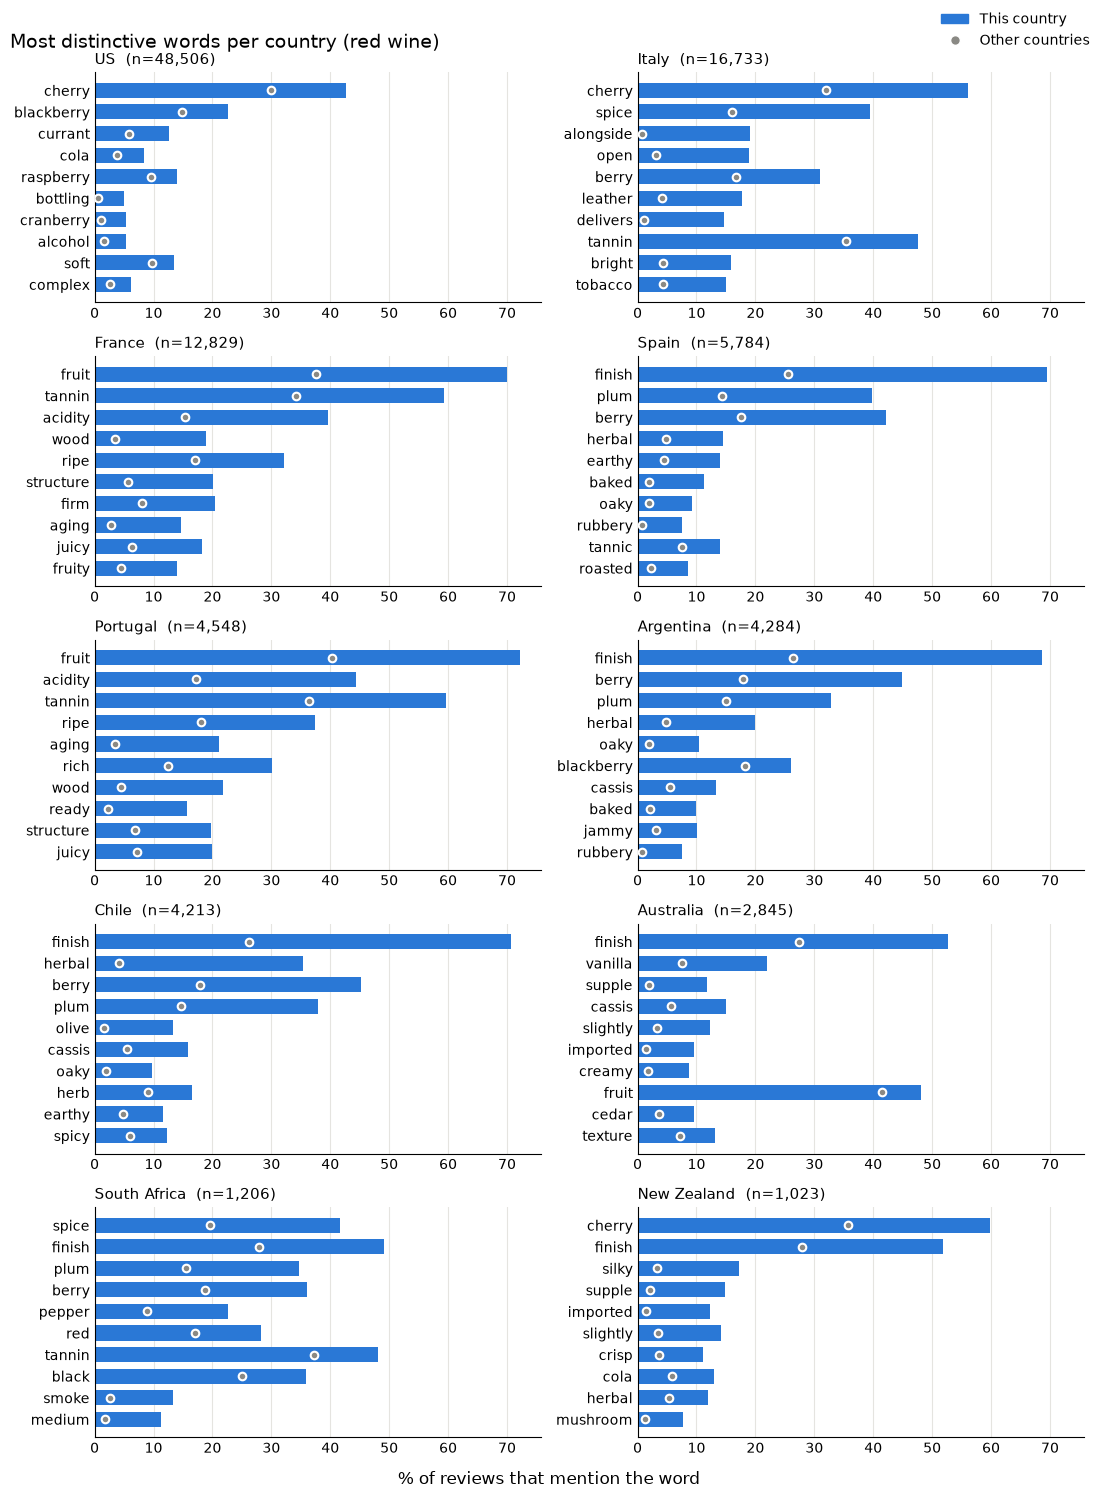

In [89]:
GROUP = "#2a78d6"   # blue bar: this country
REST  = "#8a8984"   # gray dot: the other countries

ncols = 2
nrows = math.ceil(len(countries) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3 * nrows), sharex=True)
axes = axes.flatten()

for ax, country in zip(axes, countries):
    d = distinct[country]

    ax.barh(d["word"], d["pct_group"], color=GROUP, height=0.7)
    ax.scatter(d["pct_rest"], d["word"], color=REST, s=30, zorder=3,
               edgecolor="white", linewidth=1.5)          # white ring keeps the dot visible on the bar
    ax.invert_yaxis()
    ax.set_title(f"{country}  (n={group_size[country]:,})", loc="left", fontsize=11)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.xaxis.set_tick_params(labelbottom=True)

for ax in axes[len(countries):]:
    ax.set_visible(False)

fig.legend(handles=[Patch(color=GROUP, label="This country"),
                    Line2D([], [], marker="o", color="w", markerfacecolor=REST,
                           markersize=7, label="Other countries")],
           loc="upper right", frameon=False)
fig.suptitle("Most distinctive words per country (red wine)", x=0.01, ha="left", fontsize=14)
fig.supxlabel("% of reviews that mention the word")
plt.tight_layout()
plt.show()

# Visualization White

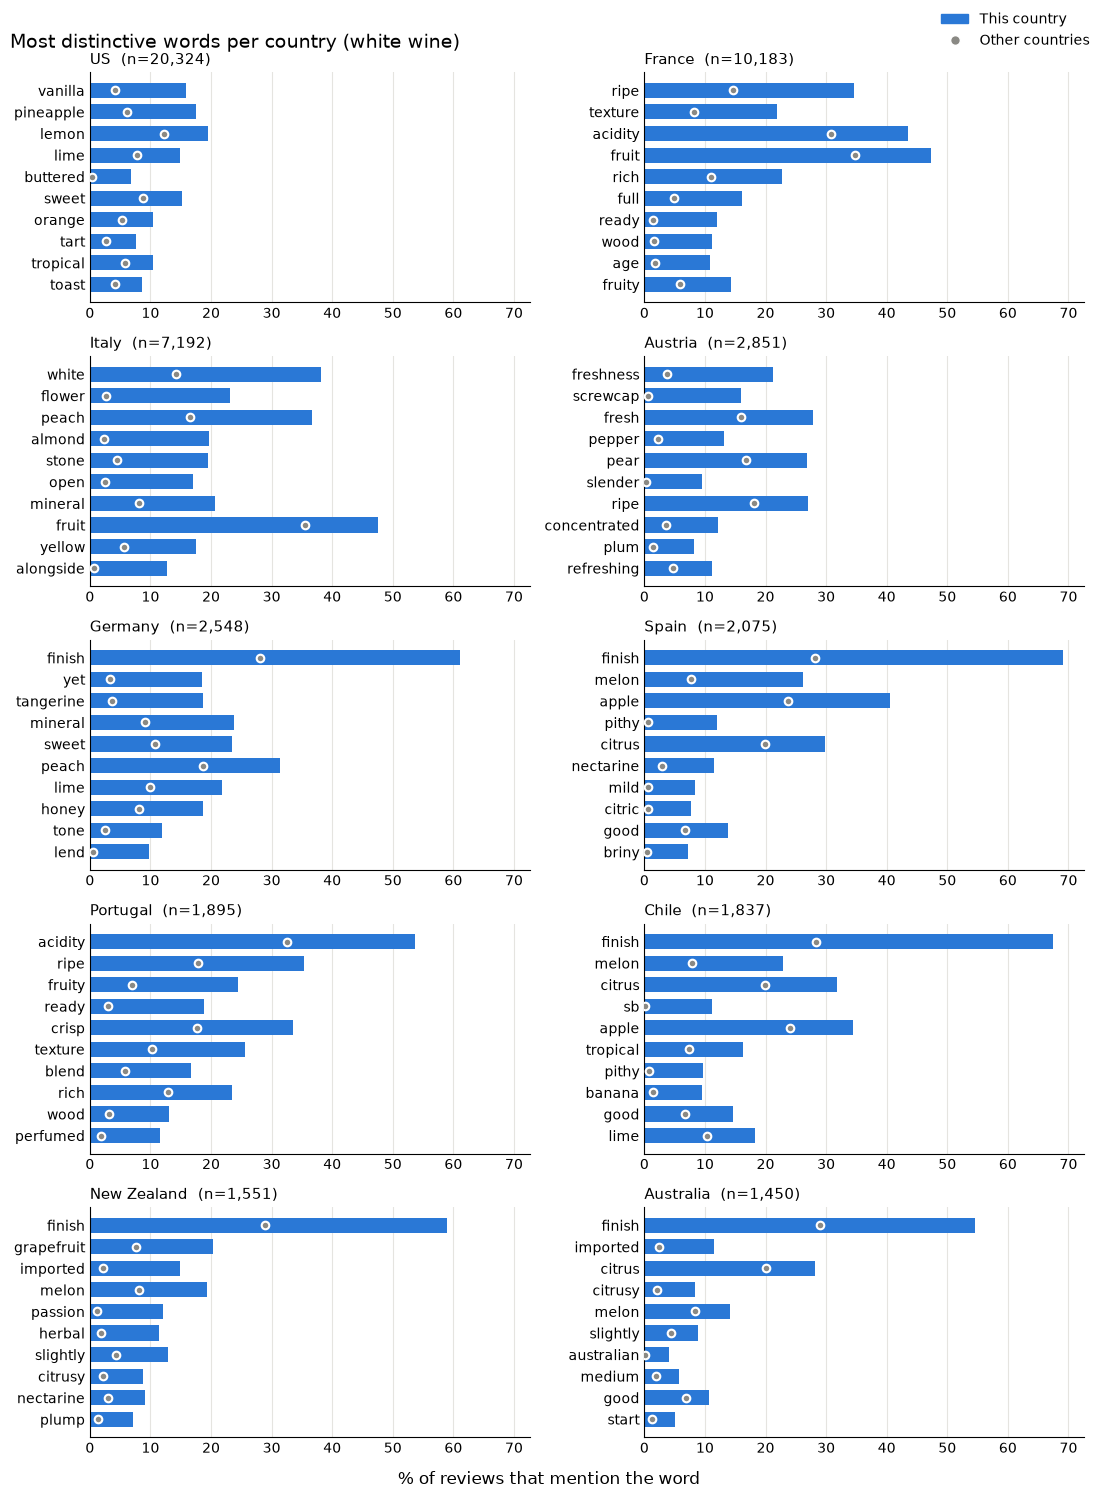

In [90]:
df_white = df[df["color"] == "white"].copy()
white_counts = (df_white.groupby("country")
                .size()
                .sort_values(ascending=False))

white_place_words = set()
for col in ["country", "province", "region_1", "region_2"]:
    for name in df_white[col].dropna().unique():
        for t in word_tokenize(name.lower()):
            if t.isalpha():
                white_place_words.add(lemmatizer.lemmatize(t))

white_place_words -= keep    # same keep set as the red section
df_white["tokens"] = df_white["tokens"].apply(lambda toks: [t for t in toks if t not in white_place_words])

white_countries = white_counts.head(10).index.tolist()
white_distinct, white_group_size = distinct_words(df_white[df_white["country"].isin(white_countries)], "country")

GROUP = "#2a78d6"   # blue bar: this country
REST  = "#8a8984"   # gray dot: the other countries

ncols = 2
nrows = math.ceil(len(white_countries) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3 * nrows), sharex=True)
axes = axes.flatten()

for ax, country in zip(axes, white_countries):
    d = white_distinct[country]

    ax.barh(d["word"], d["pct_group"], color=GROUP, height=0.7)
    ax.scatter(d["pct_rest"], d["word"], color=REST, s=30, zorder=3,
               edgecolor="white", linewidth=1.5)          # white ring keeps the dot visible on the bar
    ax.invert_yaxis()
    ax.set_title(f"{country}  (n={white_group_size[country]:,})", loc="left", fontsize=11)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.xaxis.set_tick_params(labelbottom=True)

for ax in axes[len(white_countries):]:
    ax.set_visible(False)

fig.legend(handles=[Patch(color=GROUP, label="This country"),
                    Line2D([], [], marker="o", color="w", markerfacecolor=REST,
                           markersize=7, label="Other countries")],
           loc="upper right", frameon=False)
fig.suptitle("Most distinctive words per country (white wine)", x=0.01, ha="left", fontsize=14)
fig.supxlabel("% of reviews that mention the word")
plt.tight_layout()
plt.show()

# Words & Phrases analysis (Red)

### Token Pattern...

- (?u)	Unicode-aware matching (scikit-learn’s default pattern uses this too)
- \b	word boundary, so the match starts at the start of a word
- [a-z]	the first character must be a lowercase letter
- [a-z'-]+	then one or more letters, apostrophes or hyphens
- \b	word boundary at the end

In [91]:
# Build the Phrase Vocabulary
from data_processing import WINE_WORDS
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS

negations = {"not", "no", "nor", "without"}
EDGE_STOPS = (set(ENGLISH_STOP_WORDS) - negations) | WINE_WORDS
EDGE_STOPS |= {lemmatizer.lemmatize(w) for w in EDGE_STOPS}
COUNTRY_WORDS = {
    "american", "italian", "spanish", "chilean", "australian", "aussie",
    "argentine", "argentinean", "argentinian", "portuguese", "african",
    "european", "europe", "californian", "californians", "oregonian",
    "tuscan", "tuscans", "sicilian", "burgundian", "alsatian", "sardinian",
    "patagonian", "galician", "catalan", "iberian", "iberia", "umbrian",
    "piedmontese", "provencal", "calabrian", "venetian", "lombard",
    "bordelais", "castilian", "french", "old-world", "new-world",
}
BOILERPLATE = {"varietyname", "drink"} | COUNTRY_WORDS
TOKEN_PATTERN = r"(?u)\b[a-z][a-z'-]+\b" 

df_ph_red = df_red[df_red["country"].isin(countries)].copy() # phrases for the Red wine
text = df_ph_red["description_masked"].str.lower()

counter = CountVectorizer(ngram_range=(2, 3), min_df=20, token_pattern=TOKEN_PATTERN) # grabbing the n_grams and vectorizing them and counting them
counter.fit(text)

def keep_phrase(phrase):
    """
    Used to determine what phrases are usable or not. 
    Using EDGE_STOPS: a variable that finds words that should be used start with the phrases
    """
    words = phrase.split()
    if words[0] in EDGE_STOPS or words[-1] in EDGE_STOPS:
        return False
    if "old world" in phrase or "new world" in phrase:
        return False
    return not any(w in BOILERPLATE or w in place_words for w in words)

phrases = sorted(p for p in counter.vocabulary_ if keep_phrase(p))
print(f"{len(counter.vocabulary_):,} phrases found, {len(phrases):,} kept")

40,842 phrases found, 7,851 kept


In [92]:
tfid = TfidfVectorizer(ngram_range=(2, 3), vocabulary=phrases, token_pattern=TOKEN_PATTERN, sublinear_tf=True)

X = tfid.fit_transform(text)
terms = tfid.get_feature_names_out()

TOP_N = 10
distinct_phrases = {}

for country in countries:
    mask = (df_ph_red["country"] == country).to_numpy()

    tfidf_group = np.asarray(X[mask].mean(axis=0)).ravel()
    tfidf_rest  = np.asarray(X[~mask].mean(axis=0)).ravel()
    pct_group = 100 * np.asarray((X[mask] > 0).mean(axis=0)).ravel()
    pct_rest = 100 * np.asarray((X[~mask] > 0).mean(axis=0)).ravel()

    distinct_phrases[country] = (pd.DataFrame({"phrase": terms,
                                               "pct_group": pct_group, "pct_rest": pct_rest,
                                               "diff": tfidf_group - tfidf_rest})
                                   .nlargest(TOP_N, "diff"))

distinct_phrases["Argentina"]

,phrase,pct_group,pct_rest,diff
565,berry aromas,9.010271,1.196679,0.024209
598,berry flavors,9.313725,1.986958,0.021756
811,black fruit,6.652661,2.824327,0.010983
5377,plum flavors,3.991597,1.191561,0.009810
607,berry fruit,4.831933,1.757655,0.009574
2976,flavors finish,3.361345,0.480105,0.009492
3243,fruit aromas,3.221289,0.796421,0.008246
419,baked berry,2.380952,0.234422,0.008092
3755,herbal flavors,2.614379,0.390021,0.008059
5348,plum aromas,2.614379,0.461679,0.007801


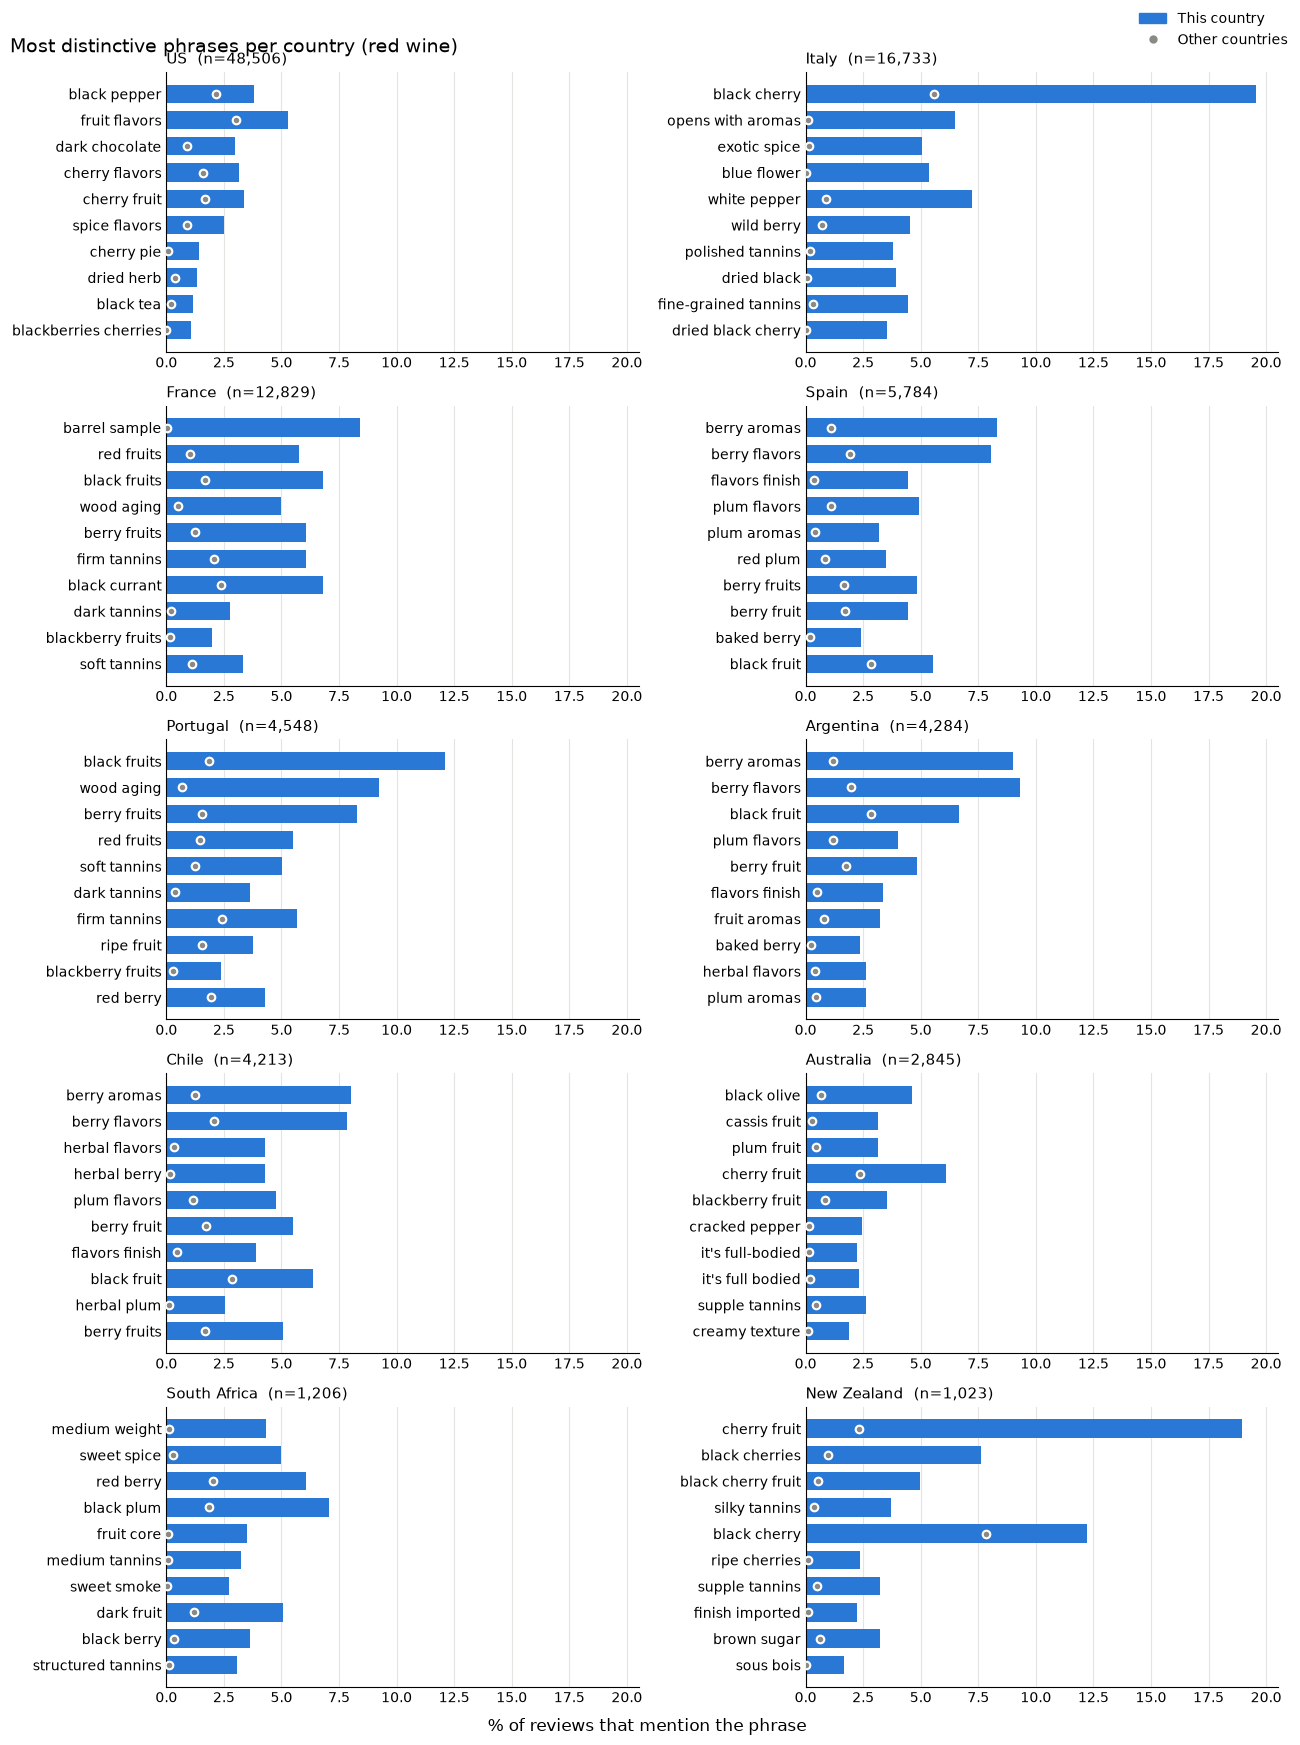

In [93]:
phrase_group_size = df_ph_red["country"].value_counts()

GROUP = "#2a78d6"
REST  = "#8a8984"

ncols = 2
nrows = math.ceil(len(countries) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.5 * nrows), sharex=True)
axes = axes.flatten()

for ax, country in zip(axes, countries):
    d = distinct_phrases[country]

    ax.barh(d["phrase"], d["pct_group"], color=GROUP, height=0.7)
    ax.scatter(d["pct_rest"], d["phrase"], color=REST, s=30, zorder=3,
               edgecolor="white", linewidth=1.5)
    ax.invert_yaxis()
    ax.set_title(f"{country}  (n={phrase_group_size[country]:,})", loc="left", fontsize=11)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.xaxis.set_tick_params(labelbottom=True)

for ax in axes[len(countries):]:
    ax.set_visible(False)

fig.legend(handles=[Patch(color=GROUP, label="This country"),
                    Line2D([], [], marker="o", color="w", markerfacecolor=REST,
                           markersize=7, label="Other countries")],
           loc="upper right", frameon=False)
fig.suptitle("Most distinctive phrases per country (red wine)", x=0.01, ha="left", fontsize=14)
fig.supxlabel("% of reviews that mention the phrase")
plt.tight_layout()
plt.show()


# Words & Phrases analysis (White)

17,342 phrases found, 2,816 kept


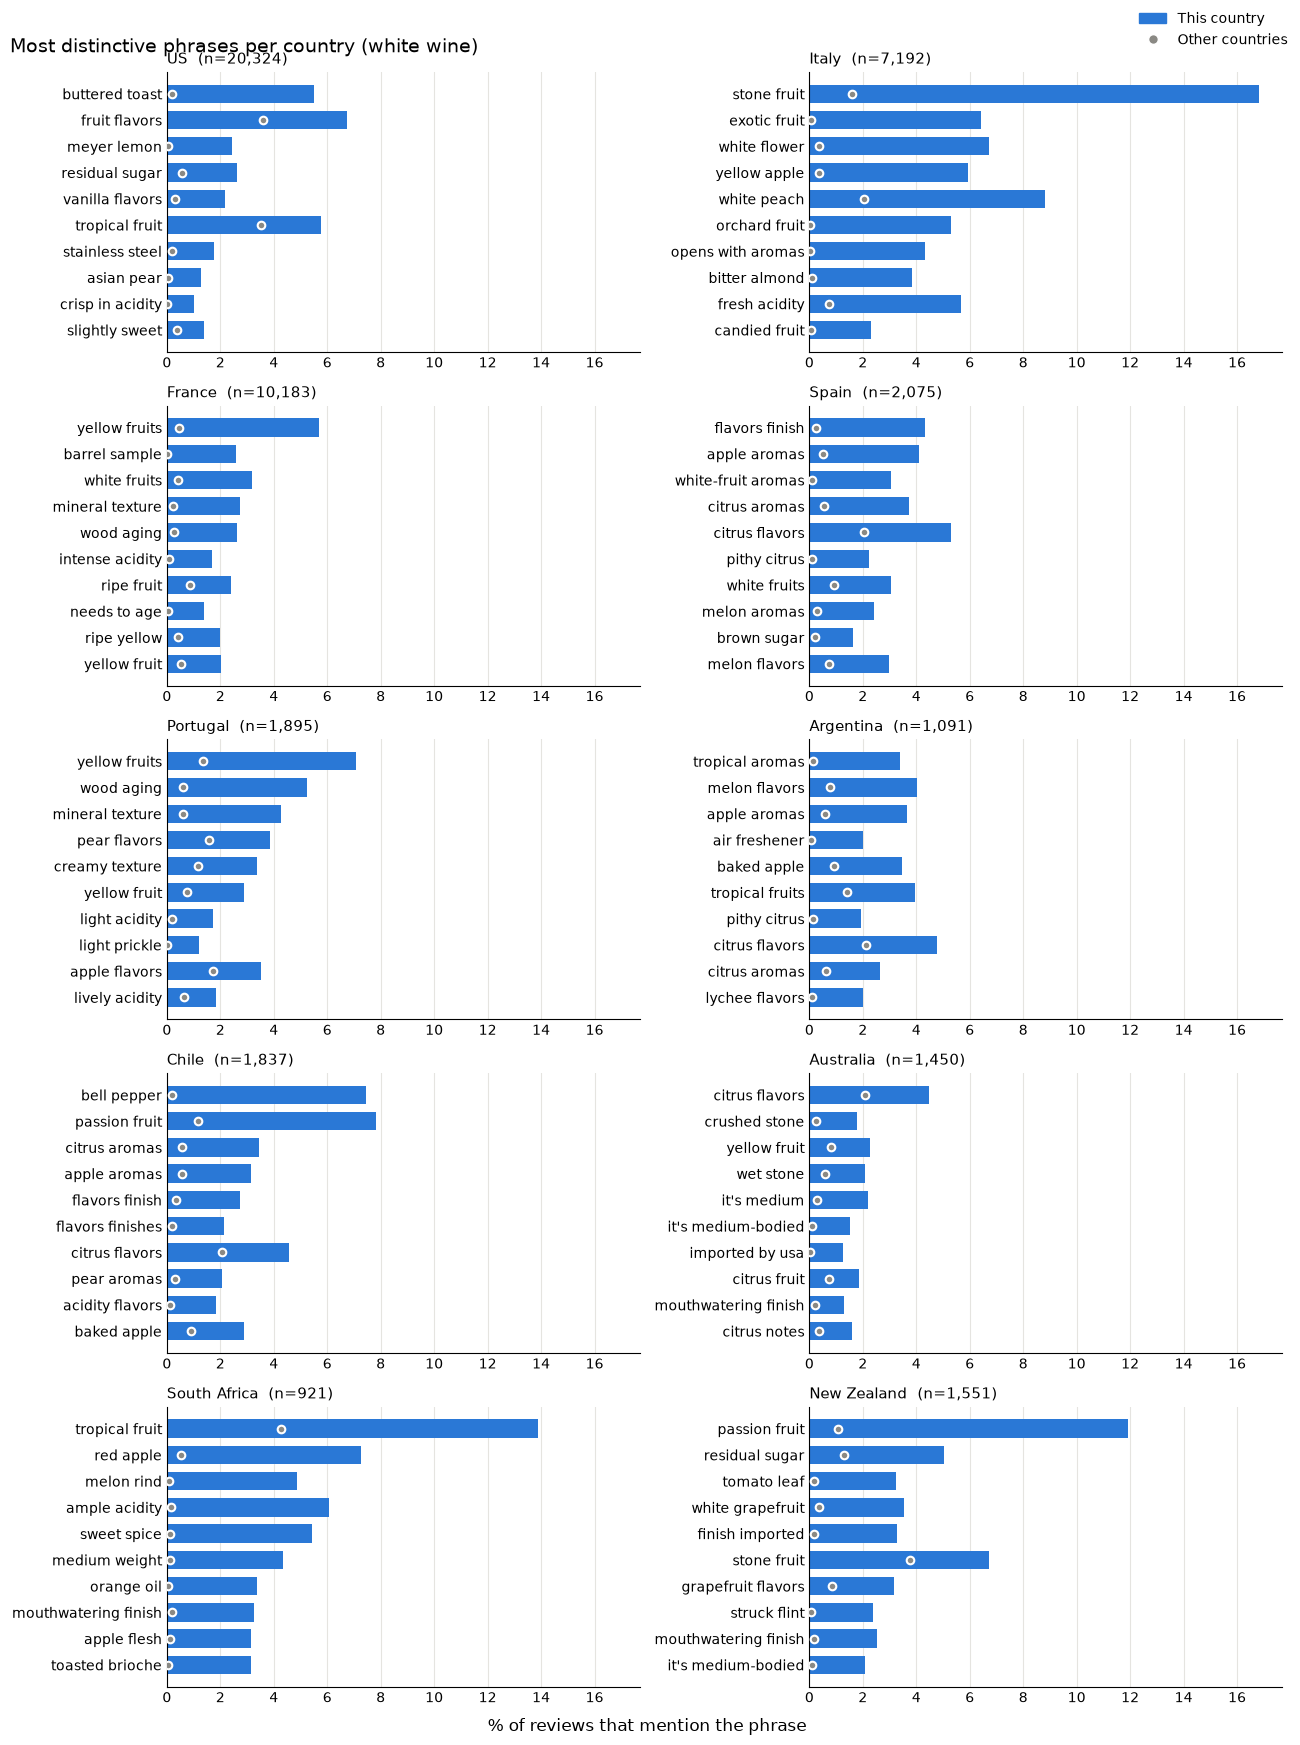

In [94]:
# Build the Phrase Vocabulary


df_ph_white = df_white[df_white["country"].isin(countries)].copy() # phrases for the Red wine
text = df_ph_white["description_masked"].str.lower()

counter = CountVectorizer(ngram_range=(2, 3), min_df=20, token_pattern=TOKEN_PATTERN) # grabbing the n_grams and vectorizing them and counting them
counter.fit(text)


phrases = sorted(p for p in counter.vocabulary_ if keep_phrase(p))
print(f"{len(counter.vocabulary_):,} phrases found, {len(phrases):,} kept")

tfid = TfidfVectorizer(ngram_range=(2, 3), vocabulary=phrases, token_pattern=TOKEN_PATTERN, sublinear_tf=True)

X = tfid.fit_transform(text)
terms = tfid.get_feature_names_out()

TOP_N = 10
distinct_phrases = {}

for country in countries:
    mask = (df_ph_white["country"] == country).to_numpy()

    tfidf_group = np.asarray(X[mask].mean(axis=0)).ravel()
    tfidf_rest  = np.asarray(X[~mask].mean(axis=0)).ravel()
    pct_group = 100 * np.asarray((X[mask] > 0).mean(axis=0)).ravel()
    pct_rest = 100 * np.asarray((X[~mask] > 0).mean(axis=0)).ravel()

    distinct_phrases[country] = (pd.DataFrame({"phrase": terms,
                                               "pct_group": pct_group, "pct_rest": pct_rest,
                                               "diff": tfidf_group - tfidf_rest})
                                   .nlargest(TOP_N, "diff"))


phrase_group_size = df_ph_white["country"].value_counts()

GROUP = "#2a78d6"
REST  = "#8a8984"

ncols = 2
nrows = math.ceil(len(countries) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.5 * nrows), sharex=True)
axes = axes.flatten()

for ax, country in zip(axes, countries):
    d = distinct_phrases[country]

    ax.barh(d["phrase"], d["pct_group"], color=GROUP, height=0.7)
    ax.scatter(d["pct_rest"], d["phrase"], color=REST, s=30, zorder=3,
               edgecolor="white", linewidth=1.5)
    ax.invert_yaxis()
    ax.set_title(f"{country}  (n={phrase_group_size[country]:,})", loc="left", fontsize=11)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.xaxis.set_tick_params(labelbottom=True)

for ax in axes[len(countries):]:
    ax.set_visible(False)

fig.legend(handles=[Patch(color=GROUP, label="This country"),
                    Line2D([], [], marker="o", color="w", markerfacecolor=REST,
                           markersize=7, label="Other countries")],
           loc="upper right", frameon=False)
fig.suptitle("Most distinctive phrases per country (white wine)", x=0.01, ha="left", fontsize=14)
fig.supxlabel("% of reviews that mention the phrase")
plt.tight_layout()
plt.show()



# ML Onto (Target = Country & red wine)
Using ML to help use further understand what phrases and words are mainly used to determine what variety of wine. 

In [95]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay 

train = df_ph_red[df_ph_red["split"] == "train"]
val = df_ph_red[df_ph_red["split"] == "val"]
test = df_ph_red[df_ph_red["split"] == "test"]

def get_text(d):
    return d["description_masked"].str.lower().str.replace(r"\b(french|american|hungarian)\s+oak\b", "oak", regex=True)

y_train, y_val, y_test = train["country"], val["country"], test["country"]


In [96]:
def build_vectorizer(train_text, ngram_range):
    counter = CountVectorizer(ngram_range=ngram_range, min_df=20, token_pattern=TOKEN_PATTERN)
    counter.fit(train_text)
    vocab = sorted(p for p in counter.vocabulary_ if keep_phrase(p))
    return TfidfVectorizer(ngram_range=ngram_range, vocabulary=vocab, token_pattern=TOKEN_PATTERN, sublinear_tf=True)

In [97]:
# Essentially our small baseline and our score that we want to beat... We saying always US
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(train), 1)), y_train)
results = {"baseline (always US)": f1_score(y_val, dummy.predict(np.zeros((len(val), 1))), average="macro")}

In [98]:
vectorizers, models = {}, {}

for name, ngrams in [("words", (1, 1)), ("words + phrases", (1, 3))]:
    vec = build_vectorizer(get_text(train), ngrams)
    X_tr = vec.fit_transform(get_text(train))
    X_va = vec.transform(get_text(val))

    model = LogisticRegression(class_weight="balanced", max_iter=2000)
    model.fit(X_tr, y_train)

    vectorizers[name], models[name] = vec, model
    results[name] = f1_score(y_val, model.predict(X_va), average="macro")
    print(f"{name}: {X_tr.shape[1]:,} features")


words: 4,209 features
words + phrases: 9,391 features


# Check (see if logic is sound)

This is just a model to see if our text model is describing the wine and not describing our review user. It 

In [99]:
taster_train = pd.get_dummies(train["taster_name"].fillna("unknown"))
taster_val = (pd.get_dummies(val["taster_name"].fillna("unknown"))
                  .reindex(columns=taster_train.columns, fill_value=0))

taster_model = LogisticRegression(class_weight="balanced", max_iter=2000).fit(taster_train, y_train)
results["taster only"] = f1_score(y_val, taster_model.predict(taster_val), average="macro")

pd.Series(results, name="macro-F1 (val)").round(3)

baseline (always US)    0.065
words                   0.596
words + phrases         0.606
taster only             0.283
Name: macro-F1 (val), dtype: float64

# Lets see what is weighted heavily

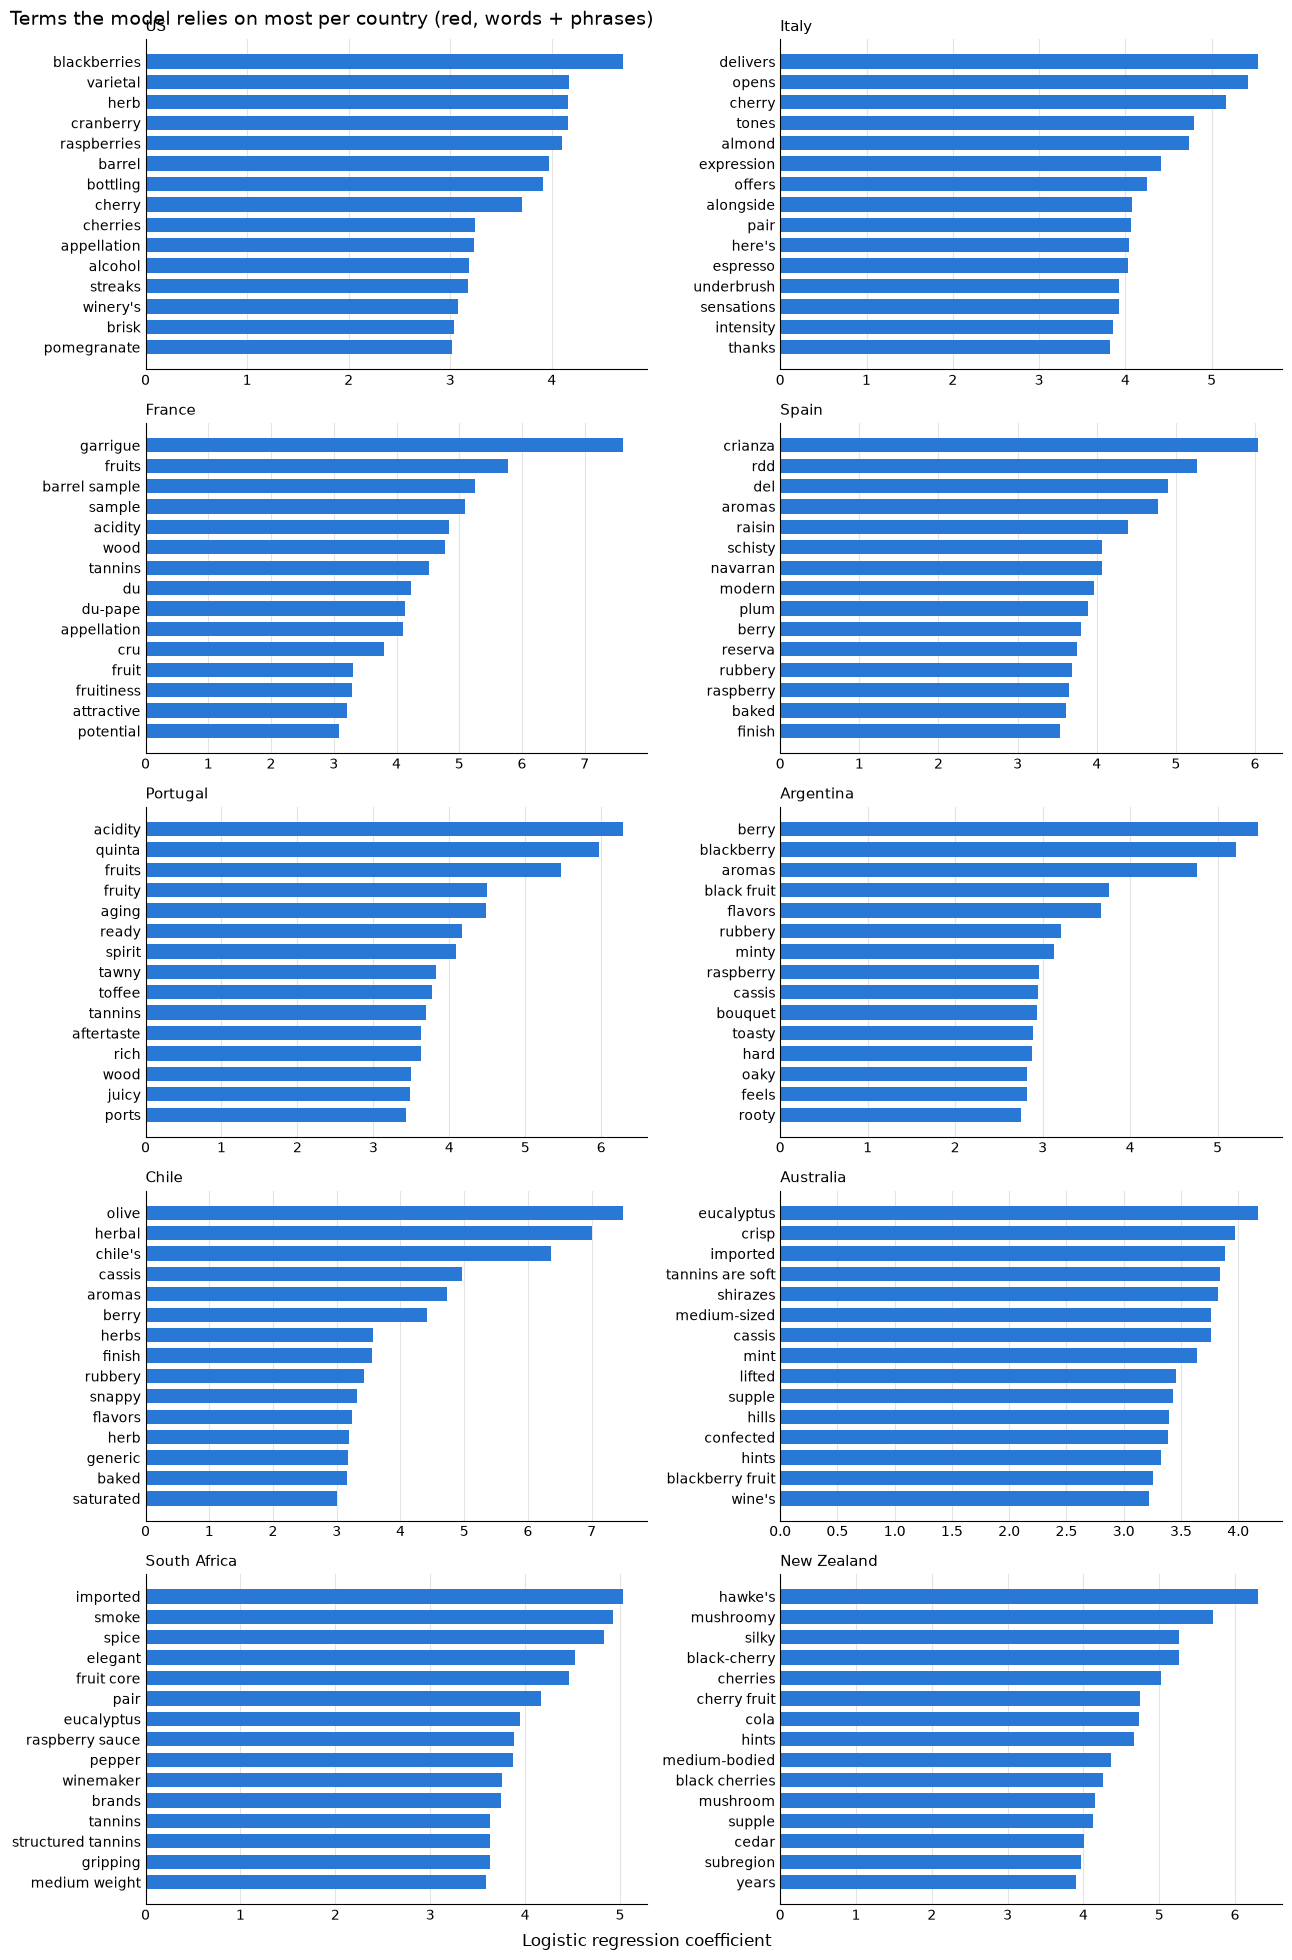

In [100]:
best = "words + phrases"
vec, model = vectorizers[best], models[best]
terms = vec.get_feature_names_out()

TOP_K = 15
top_coef = {}
for i, country in enumerate(model.classes_):
    top = np.argsort(model.coef_[i])[::-1][:TOP_K] # grabs the coefficient for each country and orders them by which one contributes the most
    top_coef[country] = pd.DataFrame({"term": terms[top], "coef": model.coef_[i][top]})

ncols = 2
nrows = math.ceil(len(countries) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
axes = axes.flatten()

for ax, country in zip(axes, countries):
    d = top_coef[country]
    ax.barh(d["term"], d["coef"], color="#2a78d6", height=0.7)
    ax.invert_yaxis()
    ax.set_title(country, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

for ax in axes[len(countries):]:
    ax.set_visible(False)

fig.suptitle(f"Terms the model relies on most per country (red, {best})", x=0.01, ha="left", fontsize=14)
fig.supxlabel("Logistic regression coefficient")
plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

   Argentina      0.376     0.426     0.399       653
   Australia      0.440     0.750     0.554       428
       Chile      0.405     0.448     0.425       630
      France      0.826     0.649     0.727      1884
       Italy      0.949     0.924     0.936      2515
 New Zealand      0.310     0.682     0.427       132
    Portugal      0.511     0.715     0.596       655
South Africa      0.422     0.804     0.553       184
       Spain      0.521     0.517     0.519       906
          US      0.972     0.897     0.933      7219

    accuracy                          0.794     15206
   macro avg      0.573     0.681     0.607     15206
weighted avg      0.827     0.794     0.805     15206



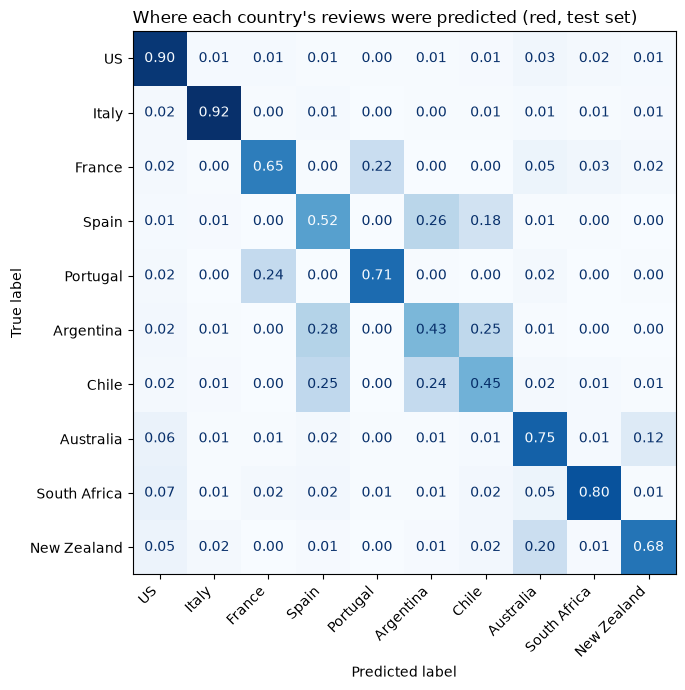

In [101]:
X_te = vec.transform(get_text(test))
pred = model.predict(X_te)

print(classification_report(y_test, pred, digits=3))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=countries, normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Where each country's reviews were predicted (red, test set)", loc="left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# ML Onto (Target = Country & white wine)

words: 2,712 features
words + phrases: 4,565 features


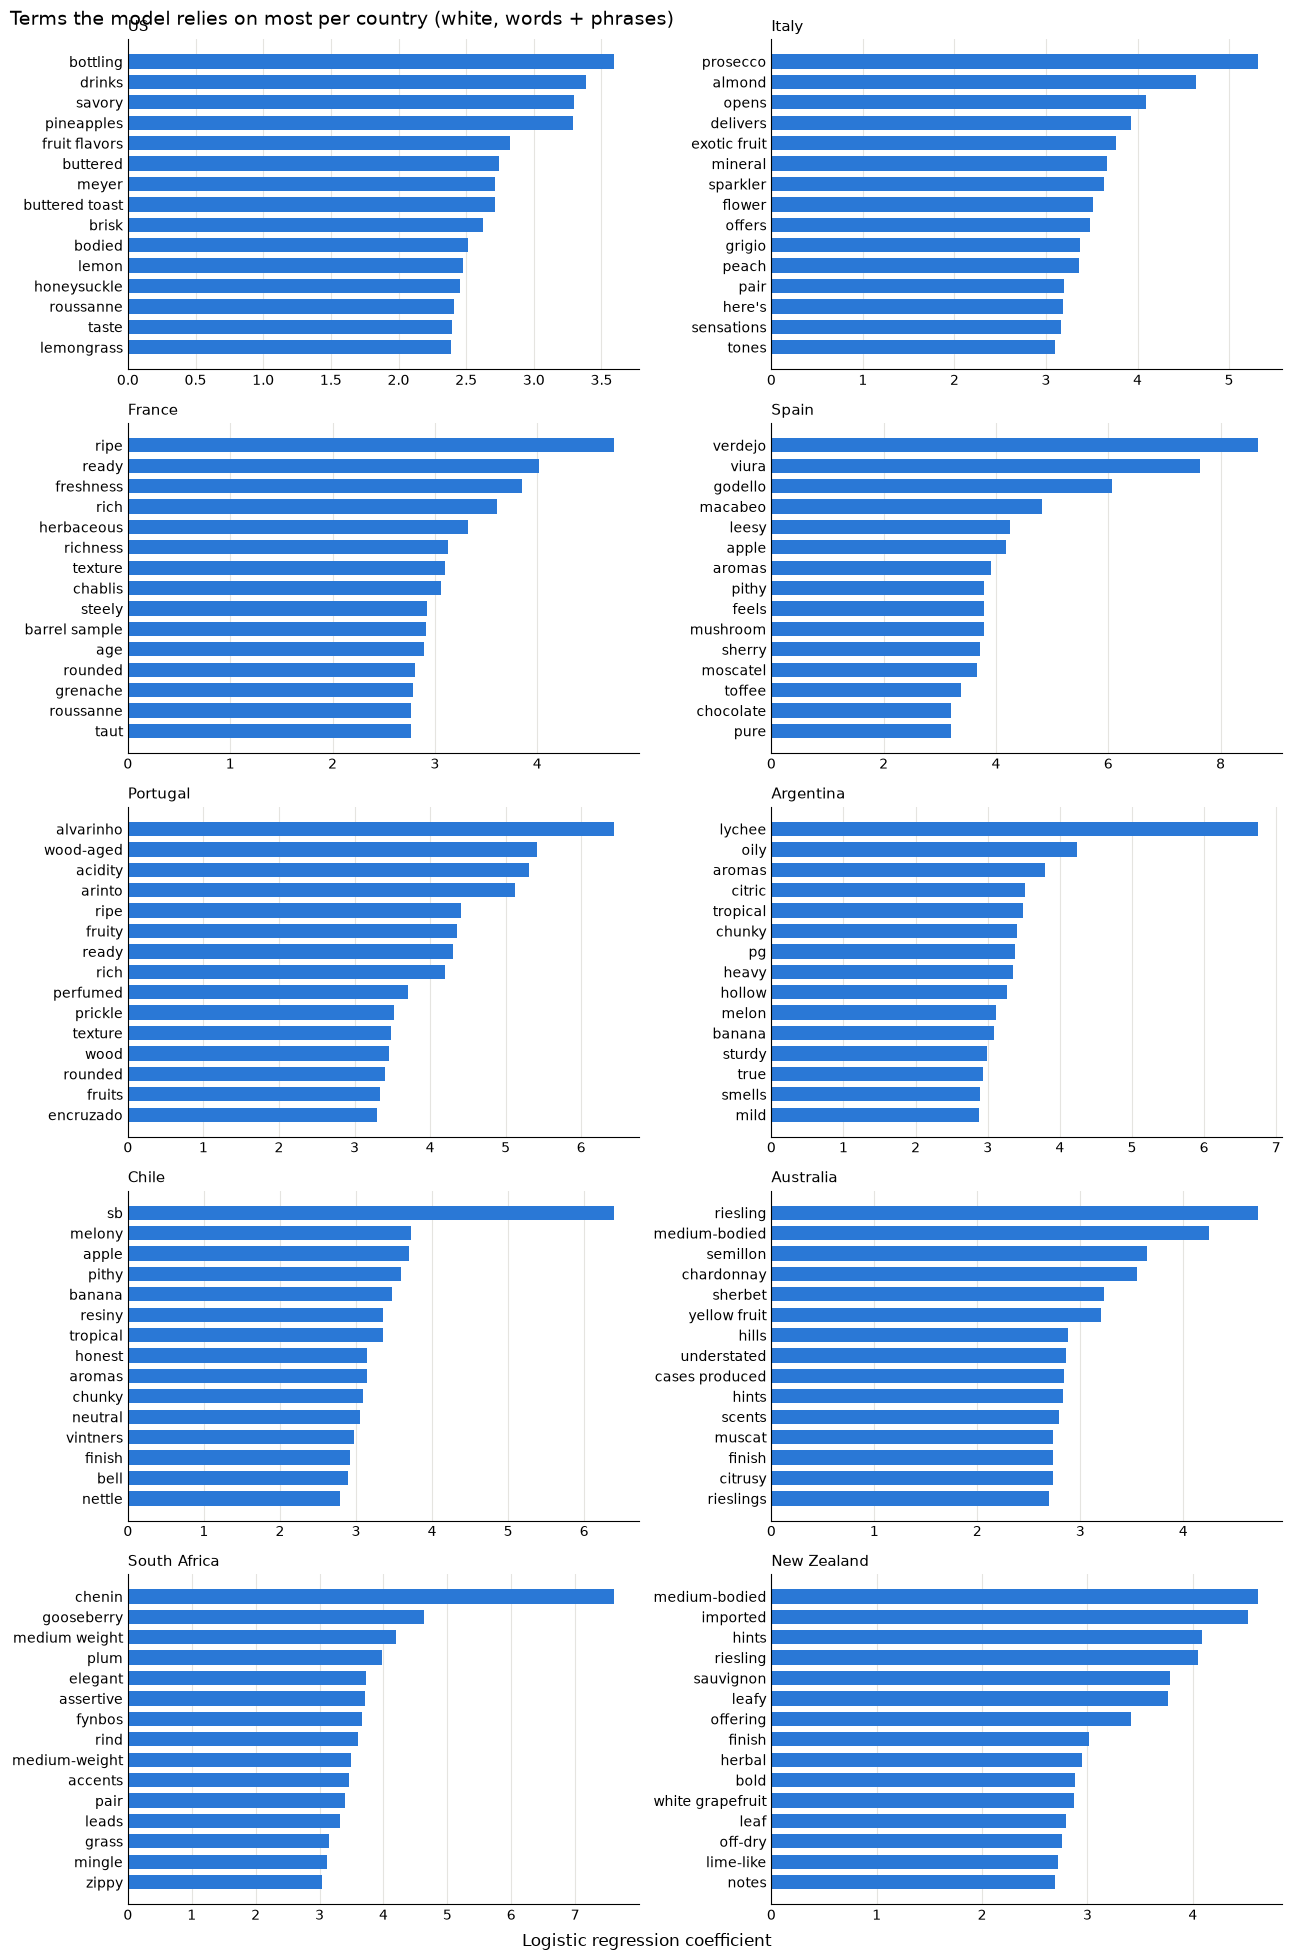

In [102]:
train = df_ph_white[df_ph_white["split"] == "train"]
val = df_ph_white[df_ph_white["split"] == "val"]
test = df_ph_white[df_ph_white["split"] == "test"]

def get_text(d):
    return d["description"].str.lower()

y_train, y_val, y_test = train["country"], val["country"], test["country"]

def build_vectorizer(train_text, ngram_range):
    counter = CountVectorizer(ngram_range=ngram_range, min_df=20, token_pattern=TOKEN_PATTERN)
    counter.fit(train_text)
    vocab = sorted(p for p in counter.vocabulary_ if keep_phrase(p))
    return TfidfVectorizer(ngram_range=ngram_range, vocabulary=vocab, token_pattern=TOKEN_PATTERN, sublinear_tf=True)

vectorizers, models = {}, {}

for name, ngrams in [("words", (1, 1)), ("words + phrases", (1, 3))]:
    vec = build_vectorizer(get_text(train), ngrams)
    X_tr = vec.fit_transform(get_text(train))
    X_va = vec.transform(get_text(val))

    model = LogisticRegression(class_weight="balanced", max_iter=2000)
    model.fit(X_tr, y_train)

    vectorizers[name], models[name] = vec, model
    results[name] = f1_score(y_val, model.predict(X_va), average="macro")
    print(f"{name}: {X_tr.shape[1]:,} features")

best = "words + phrases"
vec, model = vectorizers[best], models[best]
terms = vec.get_feature_names_out()

TOP_K = 15
top_coef = {}
for i, country in enumerate(model.classes_):
    top = np.argsort(model.coef_[i])[::-1][:TOP_K] # grabs the coefficient for each country and orders them by which one contributes the most
    top_coef[country] = pd.DataFrame({"term": terms[top], "coef": model.coef_[i][top]})

ncols = 2
nrows = math.ceil(len(countries) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
axes = axes.flatten()

for ax, country in zip(axes, countries):
    d = top_coef[country]
    ax.barh(d["term"], d["coef"], color="#2a78d6", height=0.7)
    ax.invert_yaxis()
    ax.set_title(country, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

for ax in axes[len(countries):]:
    ax.set_visible(False)

fig.suptitle(f"Terms the model relies on most per country (white, {best})", x=0.01, ha="left", fontsize=14)
fig.supxlabel("Logistic regression coefficient")
plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

   Argentina      0.333     0.506     0.402       158
   Australia      0.343     0.594     0.435       207
       Chile      0.511     0.513     0.512       275
      France      0.880     0.738     0.803      1546
       Italy      0.943     0.929     0.936      1092
 New Zealand      0.520     0.712     0.601       222
    Portugal      0.450     0.696     0.546       283
South Africa      0.496     0.836     0.622       134
       Spain      0.643     0.623     0.633       318
          US      0.952     0.862     0.905      3046

    accuracy                          0.795      7281
   macro avg      0.607     0.701     0.639      7281
weighted avg      0.834     0.795     0.809      7281



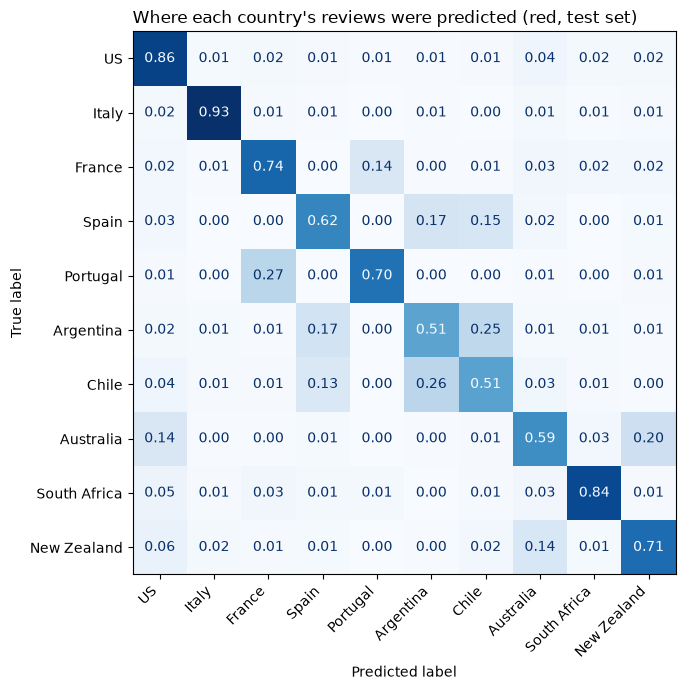

In [103]:
X_te = vec.transform(get_text(test))
pred = model.predict(X_te)

print(classification_report(y_test, pred, digits=3))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=countries, normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Where each country's reviews were predicted (red, test set)", loc="left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Issues 
1. Earlier we had data leakage in our review text. The model is tryign to predict the wine type (red or white) association to any of the ten countries the review data is from. 

To figure this out we had to explore what description can we keep that won't cause data leakage but is vital to describe the uniqueness of the wine to that country. And we had to find nicknames or words that directly described the wine's origin. For example some of the reviews named the country directly saying Spanish or French wine. This is a direct cause of data leakage. 

2. Included to our stop words and other words we believe wouldn't be beneficial to our model, we added this list of words: 

**COUNTRY_WORDS** = {
    "american", "italian", "spanish", "chilean", "australian", "aussie",
    "argentine", "argentinean", "argentinian", "portuguese", "african",
    "european", "europe", "californian", "californians", "oregonian",
    "tuscan", "tuscans", "sicilian", "burgundian", "alsatian", "sardinian",
    "patagonian", "galician", "catalan", "iberian", "iberia", "umbrian",
    "piedmontese", "provencal", "calabrian", "venetian", "lombard",
    "bordelais", "castilian", "french", "old-world", "new-world",
}

# Interesting

Whats intersting here with applying our model and understanding what words were heavily used actually revealed something different. Early into exploring the data, it was noted that the data's classes are heavily imbalanced. For example the US has 48506 reviews compared to that of New Zeland where only 1023 reviews were created. It was hypothesized that the data would fit better onto more countries that have more reviews compared to that of countries with less reviews. However, show in our confusion matrix and recall scores countries such as South Africa and New Zeland have higher recall compared to some countries such as Franche and spain that have significantly more reivews.


This begs the question, what are driving these recall scores to be highe. How come our model is able to classify South Africa and New Zeland wines better compared to countries that have signficantly more reviews? 

3. **HYPOTHESIS**: I believe its due to uniqueness of the wine that are distinguishing these wines from one another; depending on the distance each country is from one another.




# 